# Beyond Visual Quality: Sand-Specific Image Restoration as Preprocessing for Object Detection in Sandstorm Conditions

**Course:** ARTI 403 – Image Processing | **Instructor:** Dr. Manal Almouain | Imam Abdulrahman Bin Faisal University, Term 1 2026–2027

| # | Team Member | ID |
|---|-------------|----|
| 1 | Maisoon Alabdullah | 2240005251 |
| 2 | Wajd Alkhaldi | 2240005544 |
| 3 | Jolie Jamal | 2240004580 |
| 4 | Manar Alghamdi | 2240005128 |
| 5 | Daniah Alkhabbaz| 2240004129 |

## 1. Setup
Requires: `pip install ultralytics opencv-python numpy pandas matplotlib scipy`. Place this notebook next to the `DAWN` folder (`DAWN/Sand/Sand/*.jpg` and `Sand_PASCAL_VOC/*.xml`).

In [ ]:
# ---- Imports -------------------------------------------------------------
import os, time, pickle, warnings, xml.etree.ElementTree as ET
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, spearmanr
import torch
import ultralytics
from ultralytics import YOLO

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200, 'display.max_columns', 30, 'display.precision', 4)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 9})
print('OpenCV', cv2.__version__, '| Ultralytics', ultralytics.__version__, '| PyTorch', torch.__version__)

OpenCV 5.0.0 | Ultralytics 8.4.202 | PyTorch 2.15.0+cu132


In [ ]:
# ---- Configuration -------------------------------------------------------
DATA_DIR  = Path('DAWN') / 'Sand' / 'Sand'          # images
XML_DIR   = DATA_DIR / 'Sand_PASCAL_VOC'             # PASCAL VOC labels
OUT_DIR   = Path('results')
CACHE_DIR = OUT_DIR / 'cache'                        # cached detections
FIG_DIR   = OUT_DIR / 'figures'                      # figures used in the paper/slides
for d in (OUT_DIR, CACHE_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

DETECTOR        = 'yolov8n'   # main detector (pretrained on COCO, NOT re-trained)
IMGSZ           = 640         # inference size
CONF_EVAL       = 0.001       # low threshold -> full precision/recall curve for mAP
IOU_NMS         = 0.70        # NMS IoU threshold (Ultralytics default for validation)
CONF_PR         = 0.25        # operating threshold for precision / recall / F1
RUN_MULTI_MODEL = True        # also test YOLOv8s and YOLOv8m (slower on CPU, ~30 min)
SEED            = 0
torch.set_num_threads(max(os.cpu_count() or 1, 1))

assert DATA_DIR.exists(), f'Dataset folder not found: {DATA_DIR.resolve()}'


def imread(path):
    """Read an image robustly (works with non-English characters in Windows paths)."""
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)


def savefig(name):
    plt.savefig(FIG_DIR / f'{name}.png', bbox_inches='tight')


def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

## 2. Data Loading and Preprocessing
DAWN Sand subset (323 images): parse PASCAL VOC labels, map classes to COCO IDs, check consistency, export YOLO labels.

In [ ]:
# COCO class IDs of the DAWN classes (YOLOv8 was pretrained on COCO)
DAWN2COCO = {'person': 0, 'bicycle': 1, 'car': 2, 'motorcycle': 3, 'bus': 5, 'truck': 7}
CLASSES   = {v: k for k, v in DAWN2COCO.items()}


def load_voc(xml_path):
    """Return (width, height, boxes) where boxes = [[coco_cls, x1, y1, x2, y2], ...]."""
    root = ET.parse(xml_path).getroot()
    size = root.find('size')
    w, h = int(size.find('width').text), int(size.find('height').text)
    boxes = []
    for obj in root.findall('object'):
        name = obj.find('name').text.strip().lower()
        bb = obj.find('bndbox')
        boxes.append([DAWN2COCO[name]] + [float(bb.find(k).text) for k in ('xmin', 'ymin', 'xmax', 'ymax')])
    return w, h, np.array(boxes, dtype=np.float32).reshape(-1, 5)


image_paths = sorted(DATA_DIR.glob('*.jpg'))
GT, SIZES = {}, {}
for p in image_paths:
    w, h, boxes = load_voc(XML_DIR / (p.stem + '.xml'))
    GT[p.stem], SIZES[p.stem] = boxes, (w, h)
NAMES = list(GT)
print(f'Images: {len(image_paths)} | label files: {len(GT)} | objects: {sum(len(b) for b in GT.values())}')

Images: 323 | label files: 323 | objects: 2235


Images whose XML size differs from the real size: 0
Invalid / out-of-image boxes: 0


,objects,images containing class
bicycle,9,9
bus,55,38
car,1748,315
motorcycle,53,26
person,174,78
truck,196,107


Objects per image: mean 6.9, max 53
Small objects (sqrt(box area / image area) < 5%): 31.1% of all boxes


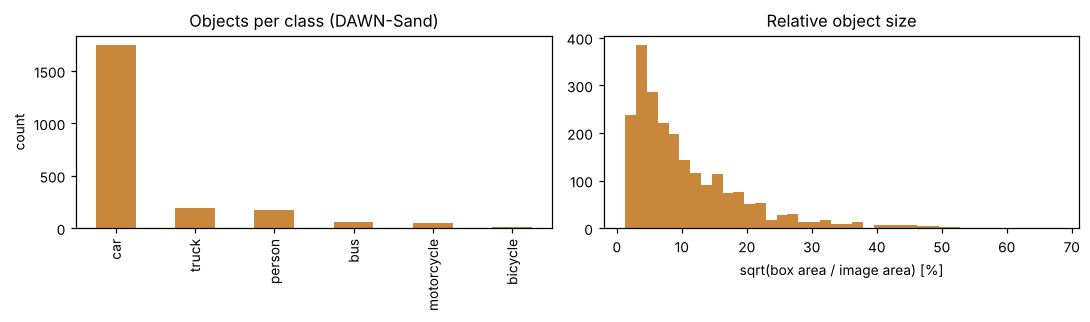

In [ ]:
# ---- Consistency checks --------------------------------------------------
bad_size, bad_box = 0, 0
for p in image_paths:
    h, w = imread(p).shape[:2]
    if (w, h) != SIZES[p.stem]:
        bad_size += 1
    b = GT[p.stem]
    bad_box += int(((b[:, 1] < 0) | (b[:, 2] < 0) | (b[:, 3] > w) | (b[:, 4] > h) | (b[:, 3] <= b[:, 1])).sum())
print('Images whose XML size differs from the real size:', bad_size)
print('Invalid / out-of-image boxes:', bad_box)

# ---- Dataset statistics --------------------------------------------------
all_boxes = np.concatenate(list(GT.values()))
counts = pd.Series([CLASSES[int(c)] for c in all_boxes[:, 0]]).value_counts()
imgs_with = {CLASSES[c]: sum((GT[n][:, 0] == c).any() for n in NAMES) for c in CLASSES}
stats = pd.DataFrame({'objects': counts, 'images containing class': pd.Series(imgs_with)})
area = (all_boxes[:, 3] - all_boxes[:, 1]) * (all_boxes[:, 4] - all_boxes[:, 2])
img_area = np.concatenate([[SIZES[n][0] * SIZES[n][1]] * len(GT[n]) for n in NAMES])
rel = np.sqrt(area / img_area)
display(stats)
print(f'Objects per image: mean {np.mean([len(b) for b in GT.values()]):.1f}, max {max(len(b) for b in GT.values())}')
print(f'Small objects (sqrt(box area / image area) < 5%): {(rel < 0.05).mean()*100:.1f}% of all boxes')

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
counts.plot.bar(ax=ax[0], color='#c8873a'); ax[0].set_title('Objects per class (DAWN-Sand)'); ax[0].set_ylabel('count')
ax[1].hist(rel * 100, bins=40, color='#c8873a'); ax[1].set_title('Relative object size'); ax[1].set_xlabel('sqrt(box area / image area) [%]')
plt.tight_layout(); savefig('fig_dataset_stats'); plt.show()

In [ ]:
# ---- Export labels in YOLO format (normalised xc, yc, w, h) ---------------
yolo_dir = OUT_DIR / 'labels_yolo_coco_ids'
yolo_dir.mkdir(exist_ok=True)
for n in NAMES:
    W, H = SIZES[n]
    lines = [f'{int(c)} {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} {(x2-x1)/W:.6f} {(y2-y1)/H:.6f}'
             for c, x1, y1, x2, y2 in GT[n]]
    (yolo_dir / f'{n}.txt').write_text('\n'.join(lines))
print('YOLO-format labels written to', yolo_dir)

YOLO-format labels written to results/labels_yolo_coco_ids


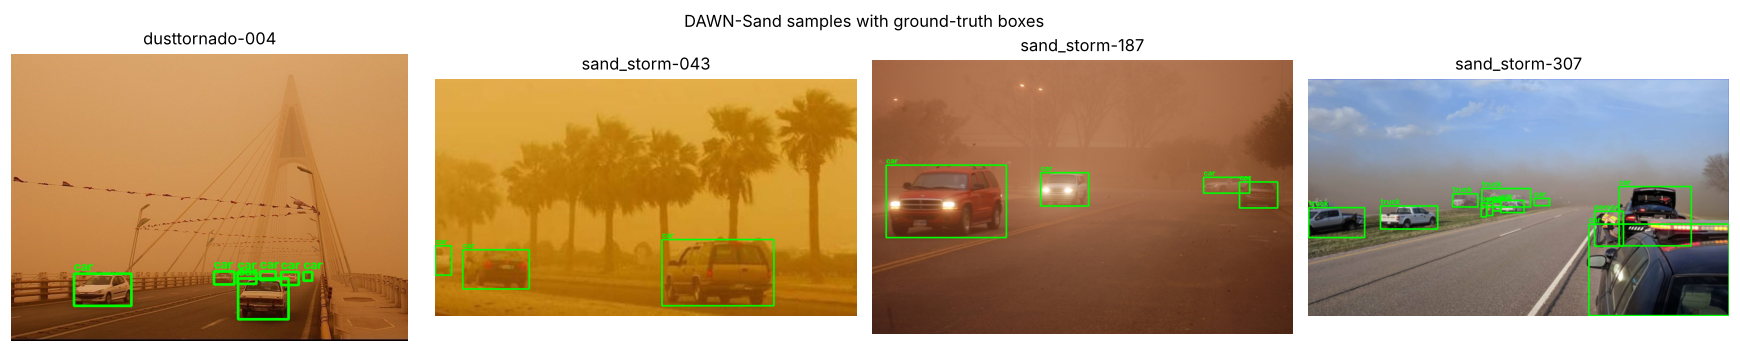

In [ ]:
# ---- Example images with ground-truth boxes -----------------------------
def draw_boxes(img, boxes, color=(0, 255, 0), with_conf=False, thick=3):
    out = img.copy()
    for b in boxes:
        if with_conf:
            x1, y1, x2, y2, conf, c = b
            label = f'{CLASSES.get(int(c), int(c))} {conf:.2f}'
        else:
            c, x1, y1, x2, y2 = b
            label = CLASSES[int(c)]
        cv2.rectangle(out, (int(x1), int(y1)), (int(x2), int(y2)), color, thick)
        cv2.putText(out, label, (int(x1), max(int(y1) - 5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)
    return out

examples = ['dusttornado-004', 'sand_storm-043', 'sand_storm-187', 'sand_storm-307']
examples = [e for e in examples if e in GT] or NAMES[:4]
fig, ax = plt.subplots(1, len(examples), figsize=(16, 3.2))
for a, n in zip(ax, examples):
    a.imshow(rgb(draw_boxes(imread(DATA_DIR / f'{n}.jpg'), GT[n]))); a.set_title(n); a.axis('off')
plt.suptitle('DAWN-Sand samples with ground-truth boxes'); plt.tight_layout(); savefig('fig_samples_gt'); plt.show()

> **Note:** labels are clean (no size mismatches or invalid boxes). The dataset is dominated by cars (1,748 of 2,235 boxes); bicycle has only 9 boxes, so its AP is unreliable.

## 3. Image Processing Methods

### 3.1 Histogram equalization, CLAHE, adaptive gamma

In [ ]:
def to_float(img):
    return img.astype(np.float32) / 255.0

def to_uint8(img):
    return np.clip(img * 255.0 + 0.5, 0, 255).astype(np.uint8)


def hist_equalization(img):
    """Global histogram equalization of the luminance (Y) channel."""
    ycc = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)
    ycc[..., 0] = cv2.equalizeHist(ycc[..., 0])
    return cv2.cvtColor(ycc, cv2.COLOR_YCrCb2BGR)


def clahe_l(img, clip=2.0, tiles=8):
    """CLAHE applied to the L channel of CIELAB."""
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tiles, tiles)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)


def adaptive_gamma(img):
    """Power-law transform; gamma maps the mean luminance to 0.5 (look-up table)."""
    y = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255.0
    m = float(np.clip(y.mean(), 0.05, 0.95))
    g = np.log(0.5) / np.log(m)
    lut = np.clip(((np.arange(256) / 255.0) ** g) * 255.0, 0, 255).astype(np.uint8)
    return cv2.LUT(img, lut)

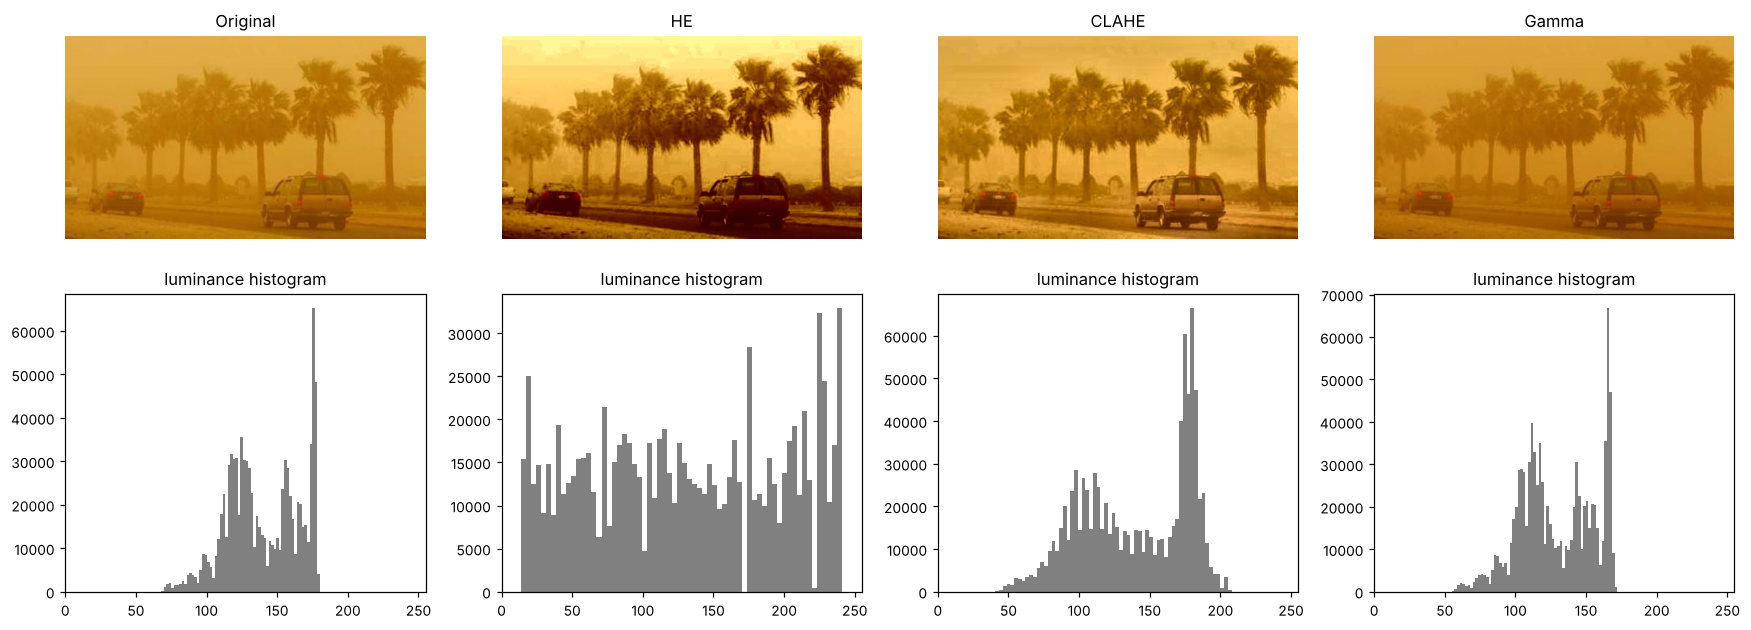

In [ ]:
# Visualise the generic methods and their luminance histograms
demo = imread(DATA_DIR / f'{examples[1]}.jpg')
variants = {'Original': demo, 'HE': hist_equalization(demo), 'CLAHE': clahe_l(demo), 'Gamma': adaptive_gamma(demo)}
fig, ax = plt.subplots(2, 4, figsize=(16, 6))
for i, (k, v) in enumerate(variants.items()):
    ax[0, i].imshow(rgb(v)); ax[0, i].set_title(k); ax[0, i].axis('off')
    ax[1, i].hist(cv2.cvtColor(v, cv2.COLOR_BGR2GRAY).ravel(), bins=64, color='gray'); ax[1, i].set_xlim(0, 255)
    ax[1, i].set_title('luminance histogram')
plt.tight_layout(); savefig('fig_intensity_methods'); plt.show()

### 3.2 Sand colour correction (channel compensation + Gray-World + Lab cast removal)

In [ ]:
def gray_world(img):
    """Gray-World white balance: every channel mean -> global mean."""
    f = to_float(img)
    means = f.reshape(-1, 3).mean(0) + 1e-6
    return to_uint8(f * (means.mean() / means))


def sand_color_correction(img, alpha=1.0, lab_shift=True):
    """Sand-specific colour correction = channel compensation + Gray-World + CIELAB a*/b* shift."""
    f = to_float(img)
    b, g, r = f[..., 0], f[..., 1], f[..., 2]
    mb, mg, mr = b.mean(), g.mean(), r.mean()
    ref, mref = (r, mr) if mr >= mg else (g, mg)            # strongest channel (red in sand)
    b = b + alpha * (mref - mb) * (1.0 - b) * ref             # (1) compensate blue
    g = g + alpha * max(mref - mg, 0) * (1.0 - g) * ref       #     compensate green if needed
    out = gray_world(to_uint8(np.clip(np.dstack([b, g, r]), 0, 1)))   # (2) Gray-World
    if lab_shift:                                             # (3) neutralise a*, b*
        lab = cv2.cvtColor(to_float(out), cv2.COLOR_BGR2LAB)
        lab[..., 1] -= lab[..., 1].mean()
        lab[..., 2] -= lab[..., 2].mean()
        out = to_uint8(np.clip(cv2.cvtColor(lab, cv2.COLOR_LAB2BGR), 0, 1))
    return out

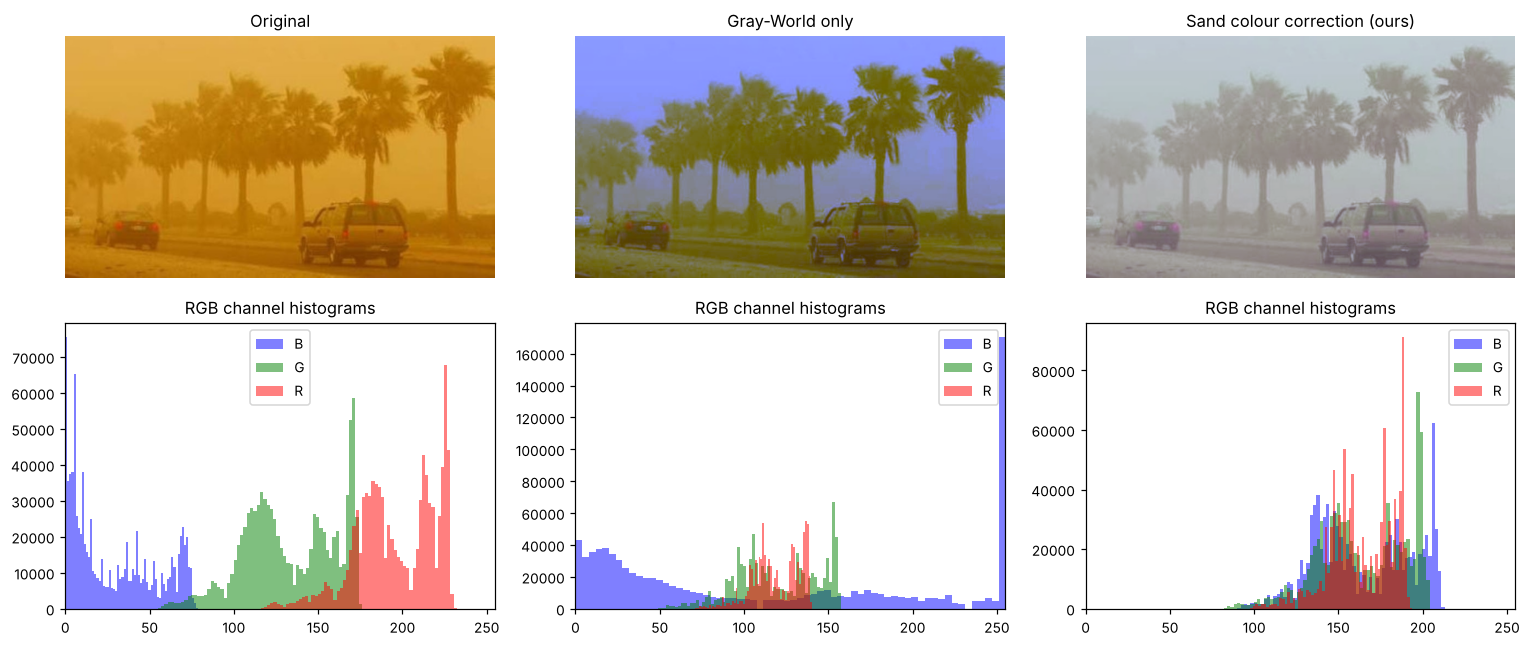

In [ ]:
# Compare Gray-World alone with the sand colour correction (images + channel histograms)
demo = imread(DATA_DIR / f'{examples[1]}.jpg')
variants = {'Original': demo, 'Gray-World only': gray_world(demo), 'Sand colour correction (ours)': sand_color_correction(demo)}
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for i, (k, v) in enumerate(variants.items()):
    ax[0, i].imshow(rgb(v)); ax[0, i].set_title(k); ax[0, i].axis('off')
    for ch, col in zip(range(3), ('b', 'g', 'r')):
        ax[1, i].hist(v[..., ch].ravel(), bins=64, color=col, alpha=0.5, label=col.upper())
    ax[1, i].set_xlim(0, 255); ax[1, i].legend(); ax[1, i].set_title('RGB channel histograms')
plt.tight_layout(); savefig('fig_color_correction'); plt.show()

> **Note:** Gray-World alone over-amplifies the almost empty blue channel (blue tint); channel compensation first avoids this.

### 3.3 Dark Channel Prior dust removal (with guided filter)

In [ ]:
def dark_channel(f, patch=15):
    """Min over colour channels followed by a min filter (= grayscale erosion)."""
    se = cv2.getStructuringElement(cv2.MORPH_RECT, (patch, patch))
    return cv2.erode(f.min(axis=2), se)


def atmospheric_light(f, dark, top=0.001):
    """Mean colour of the brightest 10% among the top-0.1% dark-channel pixels."""
    n = max(int(dark.size * top), 1)
    idx = np.argpartition(dark.ravel(), -n)[-n:]
    cand = f.reshape(-1, 3)[idx]
    k = max(len(cand) // 10, 1)
    return cand[np.argsort(cand.sum(1))[-k:]].mean(0)


def guided_filter(I, p, r, eps):
    """Guided filter (He et al., 2013) with box filters. I: guide, p: input (float32)."""
    ksize = (2 * r + 1, 2 * r + 1)
    mean = lambda x: cv2.boxFilter(x, -1, ksize, borderType=cv2.BORDER_REFLECT)
    mI, mp = mean(I), mean(p)
    a = (mean(I * p) - mI * mp) / (mean(I * I) - mI * mI + eps)
    b = mp - a * mI
    return mean(a) * I + mean(b)


def dcp_dehaze(img, omega=0.95, patch=15, t0=0.1, r=None, eps=1e-3, sky=None, sky_t=0.6):
    """DCP restoration. `sky` (optional float mask 0..1) raises the transmission floor in sky regions.
    Returns (restored image, refined transmission map, atmospheric light)."""
    f = to_float(img)
    h, w = f.shape[:2]
    r = r or max(int(0.03 * min(h, w)), 8)                  # guided-filter radius scales with image size
    A = np.maximum(atmospheric_light(f, dark_channel(f, patch)), 0.05)
    t = 1.0 - omega * dark_channel(f / A, patch)             # coarse transmission
    t = guided_filter(cv2.cvtColor(f, cv2.COLOR_BGR2GRAY), t.astype(np.float32), r, eps)
    if sky is not None:
        t = np.maximum(t, sky_t * sky + t0 * (1 - sky))
    t = np.clip(t, t0, 1.0)
    J = (f - A) / t[..., None] + A
    return to_uint8(np.clip(J, 0, 1)), t, A

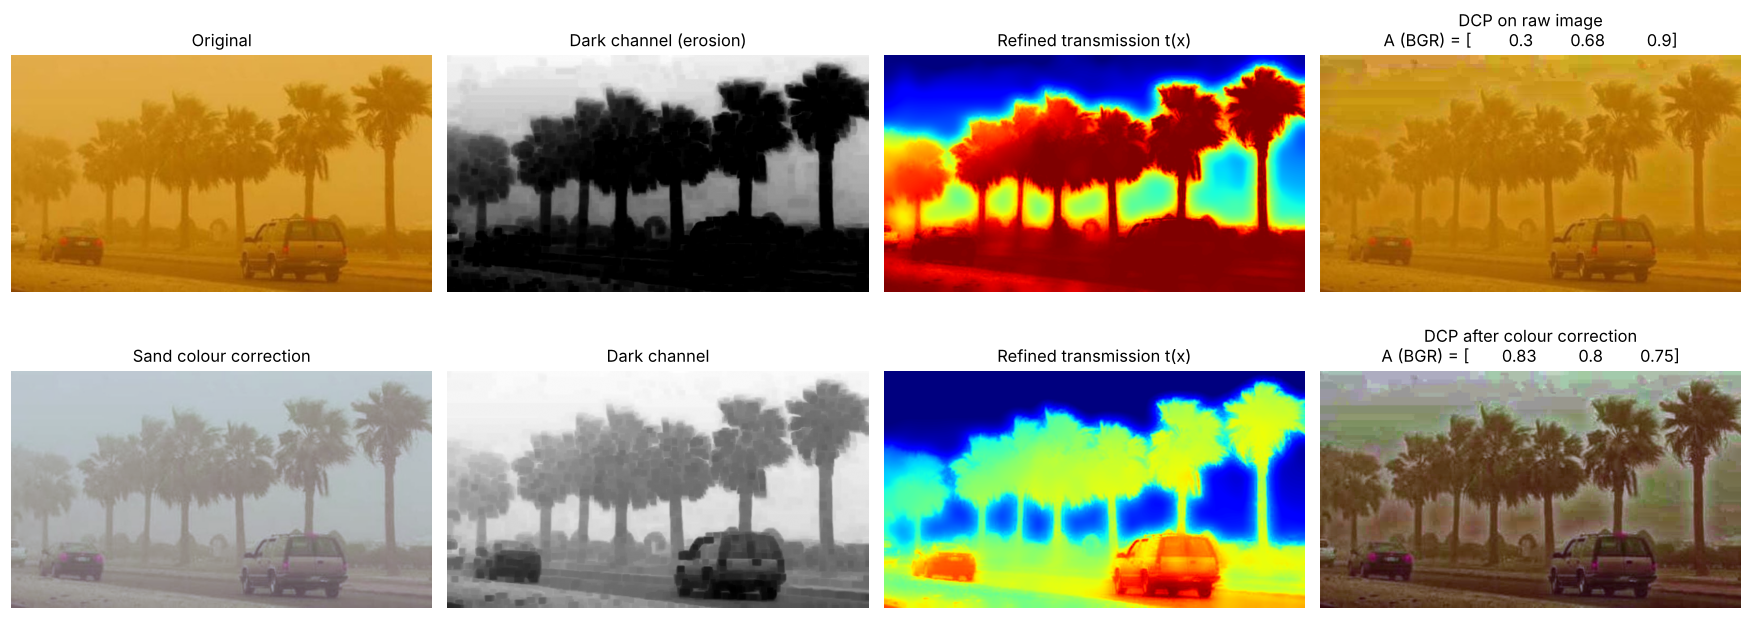

In [ ]:
# Visualise the DCP steps on the raw image and on the colour-corrected image
demo = imread(DATA_DIR / f'{examples[1]}.jpg')
J_raw, t_raw, A_raw = dcp_dehaze(demo)
cc = sand_color_correction(demo)
J_cc, t_cc, A_cc = dcp_dehaze(cc)
fig, ax = plt.subplots(2, 4, figsize=(16, 6.2))
ax[0, 0].imshow(rgb(demo)); ax[0, 0].set_title('Original')
ax[0, 1].imshow(dark_channel(to_float(demo)), cmap='gray'); ax[0, 1].set_title('Dark channel (erosion)')
ax[0, 2].imshow(t_raw, cmap='jet'); ax[0, 2].set_title('Refined transmission t(x)')
ax[0, 3].imshow(rgb(J_raw)); ax[0, 3].set_title(f'DCP on raw image\nA (BGR) = {np.round(A_raw, 2)}')
ax[1, 0].imshow(rgb(cc)); ax[1, 0].set_title('Sand colour correction')
ax[1, 1].imshow(dark_channel(to_float(cc)), cmap='gray'); ax[1, 1].set_title('Dark channel')
ax[1, 2].imshow(t_cc, cmap='jet'); ax[1, 2].set_title('Refined transmission t(x)')
ax[1, 3].imshow(rgb(J_cc)); ax[1, 3].set_title(f'DCP after colour correction\nA (BGR) = {np.round(A_cc, 2)}')
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); savefig('fig_dcp_steps'); plt.show()

> **Note:** on the raw image DCP estimates a yellow dust light *A* and keeps the cast; after colour correction *A* is neutral and the dust is removed correctly.

### 3.4 Sky segmentation (Otsu + Sobel + morphology)

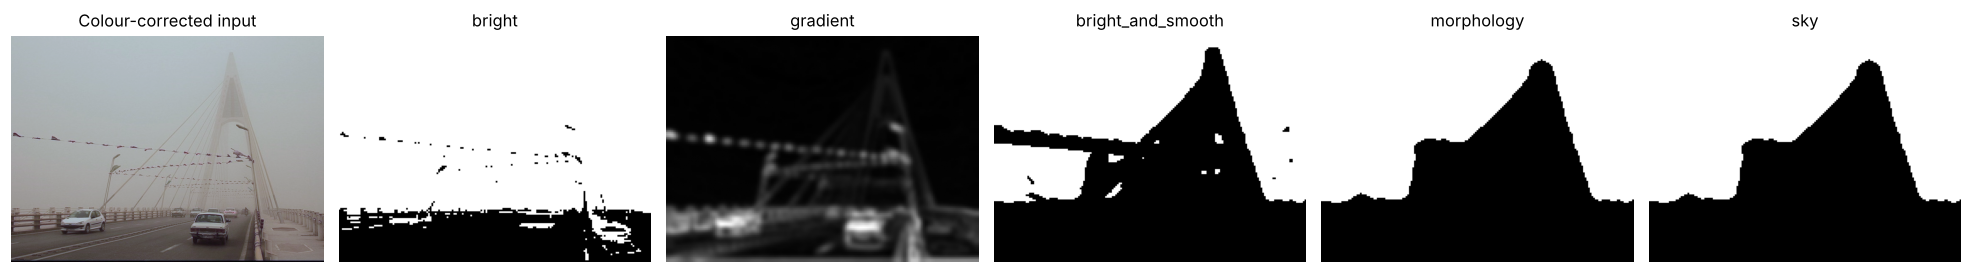

In [ ]:
def sky_mask(img, max_frac=0.6, return_steps=False):
    """Sky = bright (Otsu) AND smooth (low Sobel magnitude), opened/closed, touching the top border."""
    h, w = img.shape[:2]
    small = cv2.resize(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (w // 4, h // 4), interpolation=cv2.INTER_AREA)
    _, bright = cv2.threshold(small, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    gx = cv2.Sobel(small, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(small, cv2.CV_32F, 0, 1, ksize=3)
    mag = cv2.GaussianBlur(np.sqrt(gx * gx + gy * gy), (7, 7), 0)
    smooth = (mag < np.percentile(mag, 50)).astype(np.uint8)
    raw = (bright & smooth).astype(np.uint8)
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    m = cv2.morphologyEx(raw, cv2.MORPH_OPEN, se)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, se, iterations=2)
    n, lab, st, _ = cv2.connectedComponentsWithStats(m, 8)
    keep = np.zeros_like(m)
    for i in range(1, n):
        if st[i, cv2.CC_STAT_TOP] == 0 and st[i, cv2.CC_STAT_AREA] > 0.01 * m.size:
            keep[lab == i] = 1
    if keep.mean() > max_frac:                       # implausibly large -> not a sky region
        keep[:] = 0
    mask = cv2.GaussianBlur(cv2.resize(keep.astype(np.float32), (w, h)), (31, 31), 0)
    return (mask, dict(bright=bright, gradient=mag, bright_and_smooth=raw, morphology=m, sky=keep)) if return_steps else mask


demo = sand_color_correction(imread(DATA_DIR / f'{examples[0]}.jpg'))
mask, steps = sky_mask(demo, return_steps=True)
fig, ax = plt.subplots(1, 6, figsize=(18, 2.8))
ax[0].imshow(rgb(demo)); ax[0].set_title('Colour-corrected input')
for a, (k, v) in zip(ax[1:], steps.items()):
    a.imshow(v, cmap='gray'); a.set_title(k)
for a in ax: a.axis('off')
plt.tight_layout(); savefig('fig_sky_segmentation'); plt.show()

### 3.5 Dust severity features

Severity tertile thresholds: 0.240, 0.584


,b_star,br_ratio,contrast,severity,images
group,,,,,
light,1.882,0.992,0.161,0.147,108
moderate,17.384,0.720,0.131,0.401,107
heavy,45.376,0.282,0.132,0.734,108


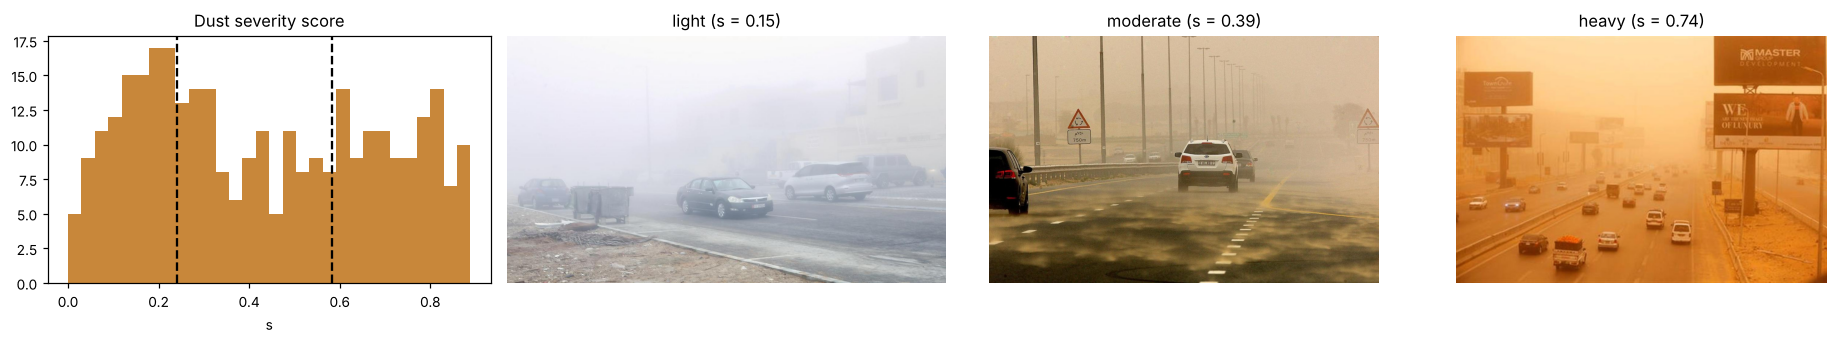

In [ ]:
def dust_features(img):
    lab = cv2.cvtColor(to_float(img), cv2.COLOR_BGR2LAB)
    m = img.reshape(-1, 3).astype(np.float32).mean(0)
    return dict(b_star=float(lab[..., 2].mean()), br_ratio=float(m[0] / (m[2] + 1e-6)),
                contrast=float(lab[..., 0].std() / 100.0))


def severity_score(img=None, feats=None):
    d = feats or dust_features(img)
    s_cast = np.clip(d['b_star'] / 40.0, 0, 1)
    s_blue = np.clip(1.0 - d['br_ratio'], 0, 1)
    s_con  = np.clip(1.0 - d['contrast'] / 0.25, 0, 1)
    return float(0.4 * s_cast + 0.3 * s_blue + 0.3 * s_con)


feat_df = pd.DataFrame({n: dust_features(imread(DATA_DIR / f'{n}.jpg')) for n in NAMES}).T
feat_df['severity'] = [severity_score(feats=r) for r in feat_df.to_dict('records')]
q1, q2 = feat_df['severity'].quantile([1/3, 2/3])
feat_df['group'] = pd.cut(feat_df['severity'], [-1, q1, q2, 2], labels=['light', 'moderate', 'heavy'])
print(f'Severity tertile thresholds: {q1:.3f}, {q2:.3f}')
display(feat_df.groupby('group', observed=True)[['b_star', 'br_ratio', 'contrast', 'severity']].mean().round(3)
        .assign(images=feat_df['group'].value_counts()))

fig, ax = plt.subplots(1, 4, figsize=(17, 3.2))
ax[0].hist(feat_df['severity'], bins=30, color='#c8873a'); ax[0].axvline(q1, c='k', ls='--'); ax[0].axvline(q2, c='k', ls='--')
ax[0].set_title('Dust severity score'); ax[0].set_xlabel('s')
for a, g in zip(ax[1:], ['light', 'moderate', 'heavy']):
    n = feat_df[feat_df.group == g]['severity'].sort_values().index[len(feat_df[feat_df.group == g]) // 2]
    a.imshow(rgb(imread(DATA_DIR / f'{n}.jpg'))); a.set_title(f'{g} (s = {feat_df.loc[n, "severity"]:.2f})'); a.axis('off')
plt.tight_layout(); savefig('fig_severity'); plt.show()

### 3.6 Full pipeline and list of compared methods

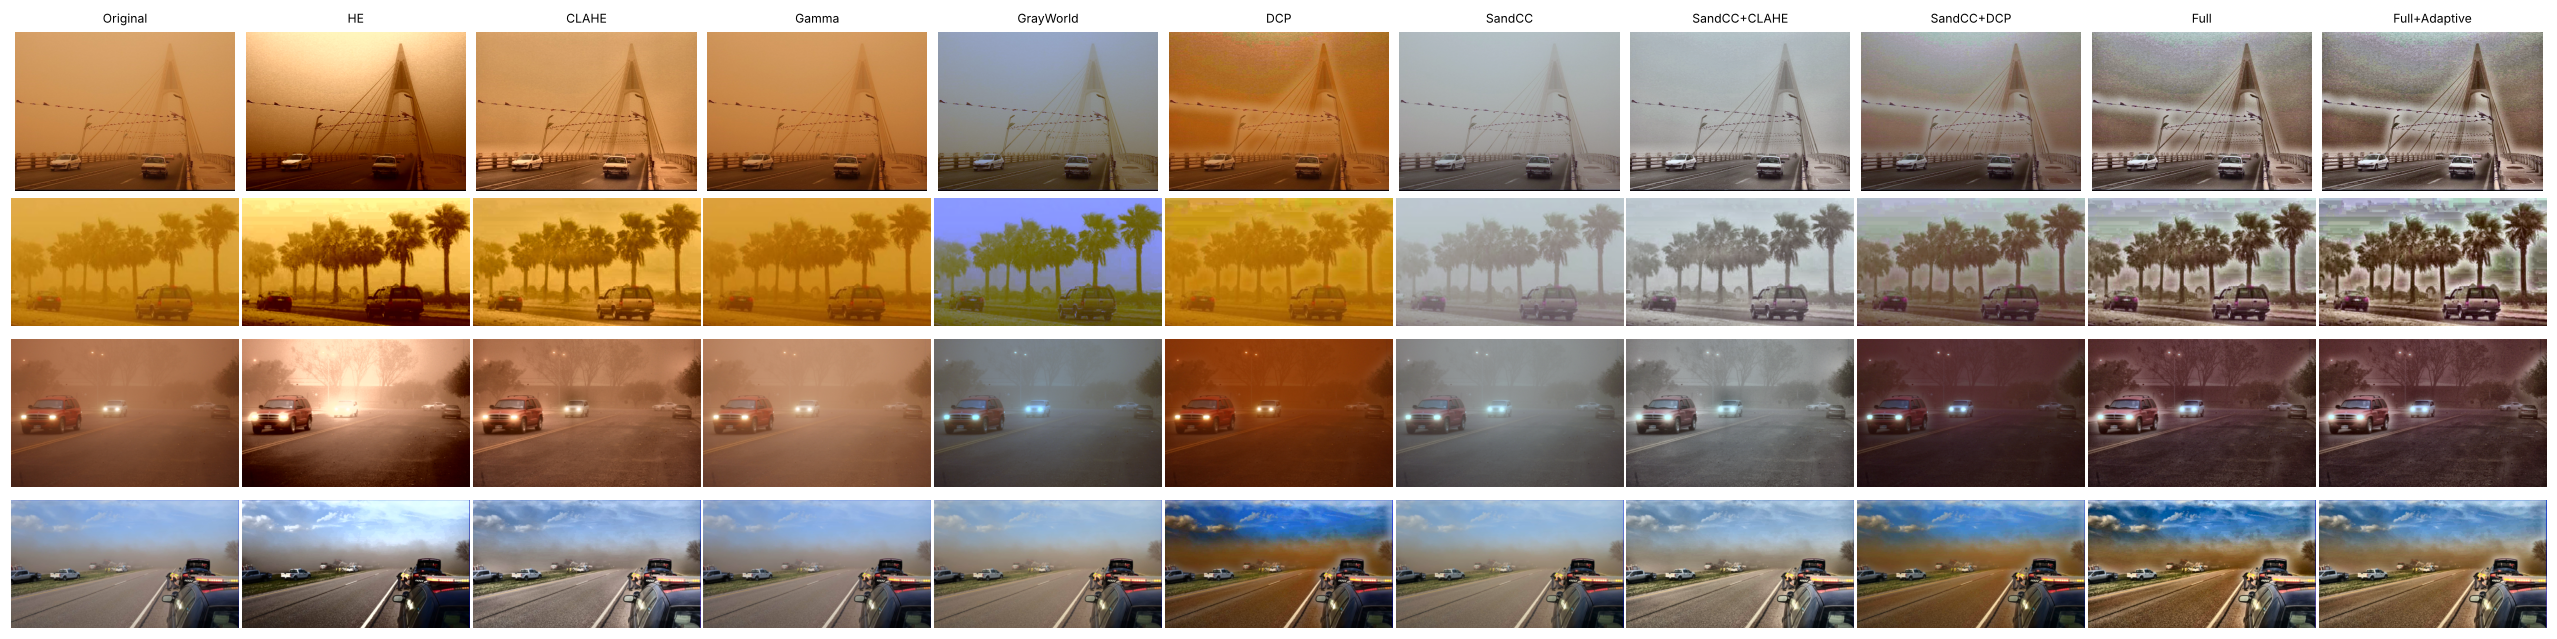

In [ ]:
def sand_pipeline(img, color=True, dehaze=True, contrast=True, sky=False, adaptive=False, omega=0.85, clip=2.0):
    """Sand-specific restoration: colour correction -> DCP -> CLAHE."""
    out = img
    if adaptive:
        s = severity_score(img)
        omega, clip = 0.70 + 0.25 * s, 1.5 + 1.5 * s
    if color:
        out = sand_color_correction(out)
    if dehaze:
        out = dcp_dehaze(out, omega=omega, sky=sky_mask(out) if sky else None)[0]
    if contrast:
        out = clahe_l(out, clip=clip)
    return out


# All preprocessing methods compared in the experiments
METHODS = {
    # --- no preprocessing
    'Original':          lambda x: x,
    # --- generic enhancement baselines
    'HE':                hist_equalization,
    'CLAHE':             clahe_l,
    'Gamma':             adaptive_gamma,
    'GrayWorld':         gray_world,
    'DCP':               lambda x: dcp_dehaze(x)[0],
    'DCP+CLAHE':         lambda x: sand_pipeline(x, color=False),   # generic combination (ablation: no colour corr.)
    # --- sand-specific (ours) + ablations
    'SandCC':            sand_color_correction,
    'SandCC+CLAHE':      lambda x: sand_pipeline(x, dehaze=False),
    'SandCC+DCP':        lambda x: sand_pipeline(x, contrast=False),
    'Full':              sand_pipeline,
    'Full+Sky':          lambda x: sand_pipeline(x, sky=True),
    'Full+Adaptive':     lambda x: sand_pipeline(x, adaptive=True),
    'Full+Sky+Adaptive': lambda x: sand_pipeline(x, sky=True, adaptive=True),
}
GENERIC = ['HE', 'CLAHE', 'Gamma', 'GrayWorld', 'DCP', 'DCP+CLAHE']   # generic methods / combinations
OURS    = ['SandCC', 'SandCC+CLAHE', 'SandCC+DCP', 'Full', 'Full+Sky', 'Full+Adaptive', 'Full+Sky+Adaptive']

# Visual comparison of all methods on 4 images
show = ['Original', 'HE', 'CLAHE', 'Gamma', 'GrayWorld', 'DCP', 'SandCC', 'SandCC+CLAHE', 'SandCC+DCP', 'Full', 'Full+Adaptive']
fig, ax = plt.subplots(len(examples), len(show), figsize=(2.1 * len(show), 1.45 * len(examples)))
for i, n in enumerate(examples):
    im = imread(DATA_DIR / f'{n}.jpg')
    im = cv2.resize(im, (640, int(640 * im.shape[0] / im.shape[1])))
    for j, m in enumerate(show):
        ax[i, j].imshow(rgb(METHODS[m](im))); ax[i, j].axis('off')
        if i == 0: ax[i, j].set_title(m, fontsize=8)
plt.tight_layout(pad=0.2); savefig('fig_methods_grid'); plt.show()

### 3.7 No-reference image-quality metrics

In [ ]:
def quality_metrics(img):
    b, g, r = [c.astype(np.float32) for c in cv2.split(img)]
    rg, yb = r - g, 0.5 * (r + g) - b
    colorful = np.sqrt(rg.std() ** 2 + yb.std() ** 2) + 0.3 * np.sqrt(rg.mean() ** 2 + yb.mean() ** 2)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3) / 8.0
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3) / 8.0
    avg_grad = np.sqrt((gx ** 2 + gy ** 2) / 2.0).mean()
    p = np.bincount(gray.ravel(), minlength=256) / gray.size
    p = p[p > 0]
    ent = -(p * np.log2(p)).sum()
    lab = cv2.cvtColor(to_float(img), cv2.COLOR_BGR2LAB)
    return dict(colorfulness=float(colorful), avg_gradient=float(avg_grad), entropy=float(ent),
                abs_a=float(abs(lab[..., 1].mean())), abs_b=float(abs(lab[..., 2].mean())))

## 4. Detection Model (pretrained YOLOv8, no training) and Evaluation

In [ ]:
IOUS = np.linspace(0.5, 0.95, 10)
_trapz = getattr(np, 'trapezoid', None) or np.trapz


def box_iou(a, b):
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def match_image(det, gt):
    """det: (N,6) [x1,y1,x2,y2,conf,cls]; gt: (M,5) [cls,x1,y1,x2,y2] -> TP flags (N,10) for the 10 IoU thresholds."""
    tp = np.zeros((len(det), len(IOUS)), bool)
    if len(det) == 0 or len(gt) == 0:
        return tp
    iou = box_iou(det[:, :4], gt[:, 1:]) * (det[:, 5][:, None] == gt[:, 0][None, :])
    order = np.argsort(-det[:, 4])
    for k, thr in enumerate(IOUS):
        used = np.zeros(len(gt), bool)
        for d in order:
            cand = np.where((iou[d] >= thr) & ~used)[0]
            if len(cand):
                used[cand[np.argmax(iou[d, cand])]] = True
                tp[d, k] = True
    return tp


def ap_101(recall, precision):
    mrec = np.concatenate([[0.0], recall, [1.0]])
    mpre = np.flip(np.maximum.accumulate(np.flip(np.concatenate([[0.0], precision, [0.0]]))))
    x = np.linspace(0, 1, 101)
    return _trapz(np.interp(x, mrec, mpre), x)


def per_image_records(dets):
    """Match once per image; the records are reused for all metrics, subsets and the bootstrap."""
    return {n: dict(conf=dets[n][:, 4], cls=dets[n][:, 5], tp=match_image(dets[n], GT[n]),
                    ngt={c: int((GT[n][:, 0] == c).sum()) for c in CLASSES}) for n in NAMES}


def metrics_from_records(recs, names=None, classes=None):
    names = NAMES if names is None else names
    classes = list(CLASSES) if classes is None else classes
    conf = np.concatenate([recs[n]['conf'] for n in names]); cls = np.concatenate([recs[n]['cls'] for n in names])
    tp = np.concatenate([recs[n]['tp'] for n in names])
    ngt = {c: sum(recs[n]['ngt'][c] for n in names) for c in CLASSES}
    ap = {}
    for c in classes:
        if ngt[c] == 0:
            continue
        m = cls == c
        t = tp[m][np.argsort(-conf[m], kind='stable')]
        ctp, cfp = np.cumsum(t, 0), np.cumsum(~t, 0)
        rec, prec = ctp / ngt[c], ctp / np.maximum(ctp + cfp, 1e-9)
        ap[c] = np.array([ap_101(rec[:, k], prec[:, k]) if len(t) else 0.0 for k in range(len(IOUS))])
    sel = (conf >= CONF_PR) & np.isin(cls, classes)
    n_tp, n_gt = tp[sel, 0].sum(), sum(ngt[c] for c in classes)
    P, R = n_tp / max(sel.sum(), 1), n_tp / max(n_gt, 1)
    out = {'mAP50': np.mean([a[0] for a in ap.values()]), 'mAP50_95': np.mean([a.mean() for a in ap.values()]),
           'P': P, 'R': R, 'F1': 2 * P * R / max(P + R, 1e-9)}
    out.update({f'AP50_{CLASSES[c]}': a[0] for c, a in ap.items()})
    return out


def per_image_f1(rec):
    sel = rec['conf'] >= CONF_PR
    n_tp, n_det, n_gt = rec['tp'][sel, 0].sum(), sel.sum(), sum(rec['ngt'].values())
    P, R = n_tp / max(n_det, 1), n_tp / max(n_gt, 1)
    return 2 * P * R / max(P + R, 1e-9)

In [ ]:
_models = {}

def get_model(name):
    if name not in _models:
        _models[name] = YOLO(f'{name}.pt')          # downloaded automatically the first time
    return _models[name]


def run_method(method, detector=DETECTOR, with_quality=True):
    """Preprocess every image with `method`, run the pretrained detector, cache detections + timings + quality."""
    cache = CACHE_DIR / f'{detector}__{method.replace("+", "_")}.pkl'
    if cache.exists():
        return pickle.load(open(cache, 'rb'))
    model, fn = get_model(detector), METHODS[method]
    dets, quality, t_pre, t_det = {}, {}, [], []
    for n in NAMES:
        img = imread(DATA_DIR / f'{n}.jpg')
        t0 = time.perf_counter(); enh = fn(img); t_pre.append(time.perf_counter() - t0)
        t0 = time.perf_counter()
        r = model.predict(enh, imgsz=IMGSZ, conf=CONF_EVAL, iou=IOU_NMS, classes=list(CLASSES),
                          max_det=300, verbose=False, device='cpu')[0]
        t_det.append(time.perf_counter() - t0)
        b = r.boxes
        dets[n] = np.hstack([b.xyxy.cpu().numpy(), b.conf.cpu().numpy()[:, None], b.cls.cpu().numpy()[:, None]]).astype(np.float32)
        if with_quality:
            quality[n] = quality_metrics(enh)
    res = dict(dets=dets, quality=quality, t_pre=np.mean(t_pre), t_det=np.mean(t_det))
    pickle.dump(res, open(cache, 'wb'))
    return res

Check of our evaluation code against the Ultralytics validator:

In [ ]:
import yaml, logging
from ultralytics.utils import LOGGER
LOGGER.setLevel(logging.WARNING)                     # silence the progress bar
val_root = OUT_DIR / 'ultralytics_val'
(val_root / 'images').mkdir(parents=True, exist_ok=True); (val_root / 'labels').mkdir(exist_ok=True)
for n in NAMES:                                        # copy images + YOLO labels into the Ultralytics layout
    dst = val_root / 'images' / f'{n}.jpg'
    if not dst.exists():
        dst.write_bytes((DATA_DIR / f'{n}.jpg').read_bytes())
    (val_root / 'labels' / f'{n}.txt').write_text((yolo_dir / f'{n}.txt').read_text())
yaml.safe_dump({'path': str(val_root.resolve()), 'train': 'images', 'val': 'images',
                'names': get_model(DETECTOR).names}, open(val_root / 'data.yaml', 'w'))
v = get_model(DETECTOR).val(data=str(val_root / 'data.yaml'), imgsz=IMGSZ, batch=8, conf=CONF_EVAL, iou=IOU_NMS,
                            classes=list(CLASSES), device='cpu', workers=0, plots=False, verbose=False)
ours = metrics_from_records(per_image_records(run_method('Original')['dets']))
print(f'Ultralytics validator : mAP@0.5 = {v.box.map50:.4f}   mAP@0.5:0.95 = {v.box.map:.4f}')
print(f'Our evaluation code   : mAP@0.5 = {ours["mAP50"]:.4f}   mAP@0.5:0.95 = {ours["mAP50_95"]:.4f}')

Ultralytics validator : mAP@0.5 = 0.4315   mAP@0.5:0.95 = 0.2880
Our evaluation code   : mAP@0.5 = 0.4192   mAP@0.5:0.95 = 0.2859


> **Note:** our mAP is within ~1 point of the Ultralytics validator (difference due to batch letter-boxing), so the evaluation code is reliable.

## 5. Run All Methods on the 323 Images

In [ ]:
RESULTS, RECORDS = {}, {}
for m in METHODS:
    t0 = time.time()
    RESULTS[m] = run_method(m)
    RECORDS[m] = per_image_records(RESULTS[m]['dets'])
    print(f'{m:<18} done ({time.time() - t0:5.1f} s)')

Original           done (  0.5 s)


HE                 done (  1.0 s)


CLAHE              done (  0.7 s)


Gamma              done (  0.5 s)


GrayWorld          done (  0.6 s)


DCP                done (  0.9 s)


... (4 outputs left out)

Full               done (  0.9 s)


Full+Sky           done (  0.8 s)


Full+Adaptive      done (  0.7 s)


Full+Sky+Adaptive  done (  0.9 s)


## 6. Results
### 6.1 Main results (YOLOv8n)

In [ ]:
CLS5 = [c for c in CLASSES if CLASSES[c] != 'bicycle']      # bicycle has only 9 boxes -> very noisy AP
rows = {}
for m in METHODS:
    r = metrics_from_records(RECORDS[m])
    r['mAP50 (5 cls)'] = metrics_from_records(RECORDS[m], classes=CLS5)['mAP50']
    r['pre-proc. ms'] = 1000 * RESULTS[m]['t_pre']
    rows[m] = r
res = pd.DataFrame(rows).T
res['group'] = ['baseline' if m == 'Original' else 'generic' if m in GENERIC else 'ours' for m in res.index]
base = res.loc['Original']
res['ΔmAP50 vs Original'] = res['mAP50'] - base['mAP50']
main_cols = ['group', 'mAP50', 'mAP50_95', 'mAP50 (5 cls)', 'P', 'R', 'F1', 'ΔmAP50 vs Original', 'pre-proc. ms']
res[main_cols].to_csv(OUT_DIR / 'table_main_results.csv')
display(res[main_cols].style.format(precision=4, subset=main_cols[1:])
        .background_gradient(cmap='YlGn', subset=['mAP50', 'mAP50_95', 'R', 'F1']))

,group,mAP50,mAP50_95,mAP50 (5 cls),P,R,F1,ΔmAP50 vs Original,pre-proc. ms
Original,baseline,0.4192,0.2859,0.4547,0.8222,0.5069,0.6272,0.0000,0.0023
HE,generic,0.4268,0.2845,0.4889,0.7817,0.5271,0.6296,0.0076,3.2657
CLAHE,generic,0.4413,0.2981,0.5059,0.8173,0.5544,0.6606,0.0221,14.1488
Gamma,generic,0.4426,0.3025,0.4796,0.8257,0.5172,0.6360,0.0235,2.9221
GrayWorld,generic,0.3918,0.2660,0.4467,0.8231,0.5078,0.6281,-0.0274,28.2051
DCP,generic,0.4420,0.3010,0.4885,0.8360,0.5383,0.6549,0.0228,135.5689
DCP+CLAHE,generic,0.4408,0.2965,0.5037,0.8086,0.5651,0.6653,0.0217,143.2657
SandCC,ours,0.4212,0.2890,0.4766,0.8272,0.5311,0.6469,0.0020,73.2848
SandCC+CLAHE,ours,0.4575,0.3093,0.5182,0.8288,0.5763,0.6799,0.0383,84.2432
SandCC+DCP,ours,0.4636,0.3190,0.5133,0.8297,0.5732,0.6780,0.0444,192.8334


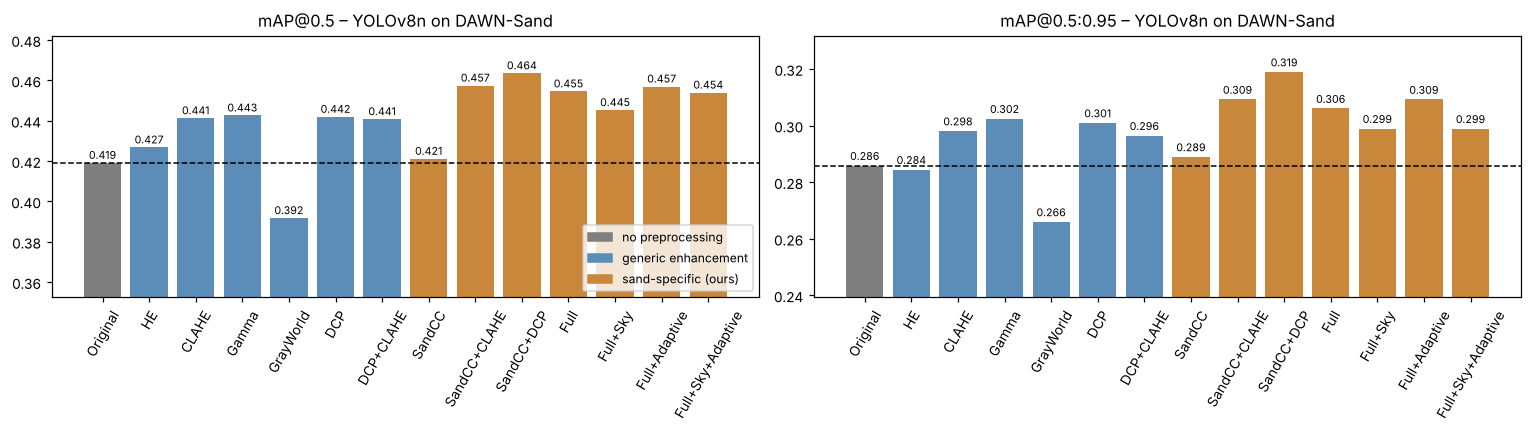

In [ ]:
colors = {'baseline': '#7f7f7f', 'generic': '#5b8db8', 'ours': '#c8873a'}
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, col in zip(ax, ['mAP50', 'mAP50_95']):
    a.bar(res.index, res[col], color=[colors[g] for g in res['group']])
    a.axhline(base[col], color='k', ls='--', lw=1, label='Original')
    a.set_title(col.replace('mAP50_95', 'mAP@0.5:0.95').replace('mAP50', 'mAP@0.5') + ' – YOLOv8n on DAWN-Sand')
    a.set_ylim(res[col].min() * 0.9, res[col].max() * 1.04); a.tick_params(axis='x', rotation=60)
    for i, v in enumerate(res[col]): a.text(i, v + 0.002, f'{v:.3f}', ha='center', fontsize=7)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax[0].legend(handles, ['no preprocessing', 'generic enhancement', 'sand-specific (ours)'], loc='lower right', fontsize=8)
plt.tight_layout(); savefig('fig_main_map'); plt.show()

> **Note:** every sand-specific pipeline without the sky mask beats the original images and all generic methods. Best: colour correction + DCP (mAP@0.5 0.464 vs. 0.419 original, 0.443 best generic).

### 6.2 Per-class AP@0.5

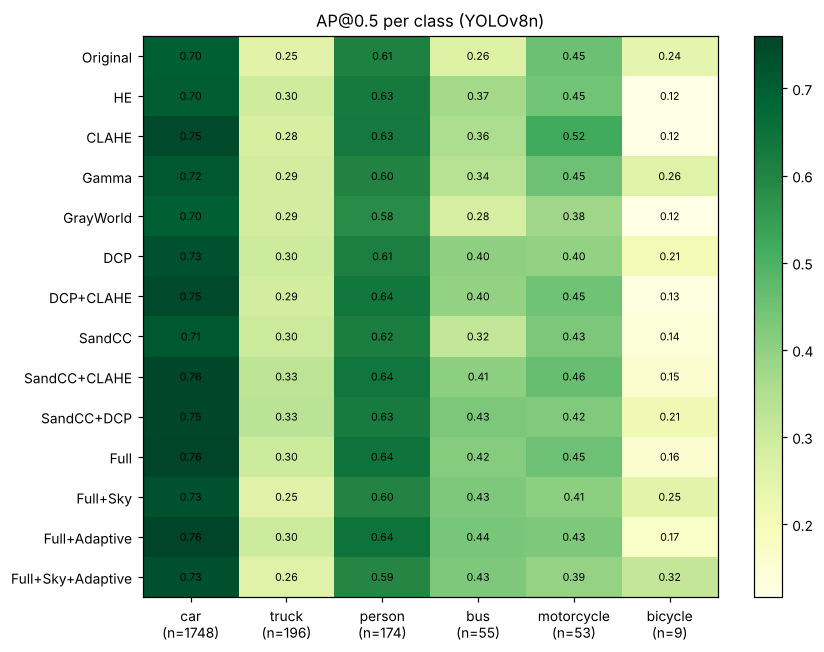

In [ ]:
pc = res[[f'AP50_{CLASSES[c]}' for c in CLASSES]].copy()
pc.columns = [c.replace('AP50_', '') for c in pc.columns]
pc = pc[['car', 'truck', 'person', 'bus', 'motorcycle', 'bicycle']]
pc.columns = [f'{c}\n(n={int(counts[c])})' for c in pc.columns]
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(pc.values, cmap='YlGn', aspect='auto')
ax.set_xticks(range(pc.shape[1]), pc.columns); ax.set_yticks(range(pc.shape[0]), pc.index)
for i in range(pc.shape[0]):
    for j in range(pc.shape[1]):
        ax.text(j, i, f'{pc.values[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im); ax.set_title('AP@0.5 per class (YOLOv8n)')
plt.tight_layout(); savefig('fig_per_class_ap'); plt.show()

### 6.3 Statistical significance (Wilcoxon + paired bootstrap)

In [ ]:
rng = np.random.default_rng(SEED)
B = 1000
boot_idx = [rng.choice(len(NAMES), len(NAMES), replace=True) for _ in range(B)]

def boot_diff(m, ref='Original'):
    diffs = []
    for idx in boot_idx:
        names = [NAMES[i] for i in idx]
        # duplicate names are allowed: build records keyed by position
        ra = {k: RECORDS[m][n] for k, n in enumerate(names)}
        rb = {k: RECORDS[ref][n] for k, n in enumerate(names)}
        diffs.append(metrics_from_records(ra, names=list(ra))['mAP50'] - metrics_from_records(rb, names=list(rb))['mAP50'])
    return np.percentile(diffs, [2.5, 97.5]), np.mean(np.array(diffs) > 0)

f1_base = np.array([per_image_f1(RECORDS['Original'][n]) for n in NAMES])
sig = {}
for m in list(METHODS)[1:]:
    f1 = np.array([per_image_f1(RECORDS[m][n]) for n in NAMES])
    p = wilcoxon(f1, f1_base, zero_method='zsplit').pvalue
    ci, p_pos = boot_diff(m)
    sig[m] = {'mean img-F1': f1.mean(), 'Δ img-F1': f1.mean() - f1_base.mean(), 'Wilcoxon p': p,
              'images better': int((f1 > f1_base).sum()), 'images worse': int((f1 < f1_base).sum()),
              'ΔmAP50': res.loc[m, 'ΔmAP50 vs Original'], '95% CI low': ci[0], '95% CI high': ci[1],
              'P(Δ>0)': p_pos}
sig = pd.DataFrame(sig).T
sig.to_csv(OUT_DIR / 'table_significance.csv')
display(sig.style.format({'mean img-F1': '{:.4f}', 'Δ img-F1': '{:+.4f}', 'Wilcoxon p': '{:.2e}', 'ΔmAP50': '{:+.4f}',
                          '95% CI low': '{:+.4f}', '95% CI high': '{:+.4f}', 'P(Δ>0)': '{:.3f}'}))

,mean img-F1,Δ img-F1,Wilcoxon p,images better,images worse,ΔmAP50,95% CI low,95% CI high,P(Δ>0)
HE,0.6034,+0.0008,7.93e-01,91.000000,99.000000,+0.0076,-0.0397,+0.0432,0.630
CLAHE,0.6449,+0.0423,7.22e-07,120.000000,57.000000,+0.0221,-0.0256,+0.0574,0.828
Gamma,0.6147,+0.0121,8.08e-02,60.000000,41.000000,+0.0235,-0.0006,+0.0582,0.972
GrayWorld,0.6035,+0.0009,3.58e-01,79.000000,68.000000,-0.0274,-0.0743,+0.0073,0.103
DCP,0.6363,+0.0337,1.93e-04,108.000000,59.000000,+0.0228,-0.0043,+0.0510,0.956
DCP+CLAHE,0.6430,+0.0404,1.22e-05,129.000000,72.000000,+0.0217,-0.0300,+0.0624,0.823
SandCC,0.6306,+0.0281,3.56e-04,90.000000,47.000000,+0.0020,-0.0425,+0.0348,0.574
SandCC+CLAHE,0.6705,+0.0679,5.34e-13,143.000000,48.000000,+0.0383,-0.0127,+0.0824,0.927
SandCC+DCP,0.6624,+0.0599,2.77e-09,136.000000,59.000000,+0.0444,+0.0084,+0.0841,0.989
Full,0.6619,+0.0594,3.92e-10,155.000000,67.000000,+0.0354,-0.0054,+0.0807,0.960


> **Note:** Wilcoxon p < 0.001 for all sand-specific pipelines without the sky mask; the paired-bootstrap 95% CI excludes zero only for colour correction + DCP.

### 6.4 Ablation study

In [ ]:
abl_rows = [('Original (no preprocessing)', 'Original', '–', '–', '–'),
            ('Colour correction only', 'SandCC', '✔', '–', '–'),
            ('DCP only (generic)', 'DCP', '–', '✔', '–'),
            ('CLAHE only (generic)', 'CLAHE', '–', '–', '✔'),
            ('Colour correction + CLAHE', 'SandCC+CLAHE', '✔', '–', '✔'),
            ('Colour correction + DCP', 'SandCC+DCP', '✔', '✔', '–'),
            ('DCP + CLAHE (no colour correction)', 'DCP+CLAHE', '–', '✔', '✔'),
            ('Full: colour corr. + DCP + CLAHE', 'Full', '✔', '✔', '✔'),
            ('Full + sky-aware DCP', 'Full+Sky', '✔', '✔ (sky)', '✔'),
            ('Full + severity-adaptive', 'Full+Adaptive', '✔', '✔ (adapt.)', '✔ (adapt.)'),
            ('Full + sky + adaptive', 'Full+Sky+Adaptive', '✔', '✔ (sky, adapt.)', '✔ (adapt.)')]
abl = pd.DataFrame([{'configuration': a, 'colour corr.': c, 'DCP': d, 'CLAHE': e,
                     'mAP@0.5': res.loc[m, 'mAP50'], 'mAP@0.5:0.95': res.loc[m, 'mAP50_95'],
                     'Recall': res.loc[m, 'R'], 'F1': res.loc[m, 'F1']} for a, m, c, d, e in abl_rows])
abl.to_csv(OUT_DIR / 'table_ablation.csv', index=False)
display(abl.style.format(precision=4).hide(axis='index'))

configuration,colour corr.,DCP,CLAHE,mAP@0.5,mAP@0.5:0.95,Recall,F1
Original (no preprocessing),–,–,–,0.4192,0.2859,0.5069,0.6272
Colour correction only,✔,–,–,0.4212,0.2890,0.5311,0.6469
DCP only (generic),–,✔,–,0.4420,0.3010,0.5383,0.6549
CLAHE only (generic),–,–,✔,0.4413,0.2981,0.5544,0.6606
Colour correction + CLAHE,✔,–,✔,0.4575,0.3093,0.5763,0.6799
Colour correction + DCP,✔,✔,–,0.4636,0.3190,0.5732,0.6780
DCP + CLAHE (no colour correction),–,✔,✔,0.4408,0.2965,0.5651,0.6653
Full: colour corr. + DCP + CLAHE,✔,✔,✔,0.4546,0.3061,0.5888,0.6820
Full + sky-aware DCP,✔,✔ (sky),✔,0.4453,0.2990,0.5588,0.6567
Full + severity-adaptive,✔,✔ (adapt.),✔ (adapt.),0.4570,0.3093,0.5879,0.6815


> **Note:** colour correction alone gives almost nothing (+0.2), but it nearly doubles the gain of DCP (+2.3 → +4.4). Adding CLAHE on top raises recall but not mAP.

### 6.5 Results by dust severity

,light,moderate,heavy
Original,0.4808,0.3830,0.4223
HE,0.5168,0.4239,0.4110
CLAHE,0.5435,0.4035,0.4435
Gamma,0.5298,0.4001,0.4341
GrayWorld,0.4851,0.3750,0.3819
DCP,0.5338,0.4290,0.4090
DCP+CLAHE,0.5437,0.4252,0.4162
SandCC,0.5045,0.3836,0.4423
SandCC+CLAHE,0.5605,0.4139,0.4622
SandCC+DCP,0.5480,0.4265,0.4744


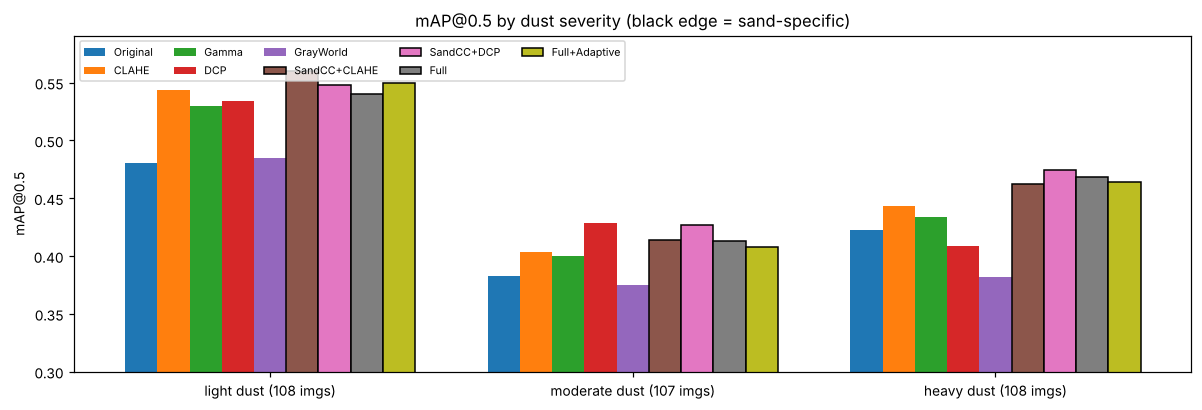

In [ ]:
groups = {g: list(feat_df.index[feat_df.group == g]) for g in ['light', 'moderate', 'heavy']}
sev_tab = pd.DataFrame({m: {g: metrics_from_records(RECORDS[m], names=ns)['mAP50'] for g, ns in groups.items()}
                        for m in METHODS}).T
sev_tab.to_csv(OUT_DIR / 'table_severity.csv')
display(sev_tab.style.format(precision=4).background_gradient(cmap='YlGn', axis=0))

sel = ['Original', 'CLAHE', 'Gamma', 'DCP', 'GrayWorld', 'SandCC+CLAHE', 'SandCC+DCP', 'Full', 'Full+Adaptive']
fig, ax = plt.subplots(figsize=(11, 3.8))
w = 0.8 / len(sel); x = np.arange(3)
cmap = plt.get_cmap('tab10')
for i, m in enumerate(sel):
    ax.bar(x + i * w, sev_tab.loc[m], w, label=m, color=cmap(i), edgecolor='k' if m in OURS else None)
ax.set_xticks(x + w * (len(sel) - 1) / 2, [f'{g} dust ({len(groups[g])} imgs)' for g in groups])
ax.set_ylabel('mAP@0.5'); ax.set_ylim(0.3, sev_tab.loc[sel].values.max() + 0.03)
ax.legend(ncol=5, fontsize=7, loc='upper left'); ax.set_title('mAP@0.5 by dust severity (black edge = sand-specific)')
plt.tight_layout(); savefig('fig_severity_map'); plt.show()

> **Note:** in heavy dust generic DCP (and HE) are worse than no preprocessing, while colour correction + DCP gives the largest gain (0.474 vs. 0.422).

### 6.6 Image-quality metrics vs. detection accuracy

,colorfulness,avg_gradient,entropy,abs_a,abs_b,mAP50
Original,33.768,1.156,6.595,8.638,22.157,0.419
HE,36.039,2.506,6.592,7.983,20.303,0.427
CLAHE,33.965,2.432,6.883,8.577,22.042,0.441
Gamma,37.438,1.280,6.728,9.874,23.870,0.443
GrayWorld,23.950,1.202,6.568,0.608,1.389,0.392
DCP,50.983,1.992,6.715,11.956,27.651,0.442
DCP+CLAHE,45.856,3.645,7.136,10.788,25.873,0.441
SandCC,12.121,1.161,6.565,0.075,0.089,0.421
SandCC+CLAHE,12.119,2.426,6.873,0.088,0.109,0.457
SandCC+DCP,26.985,1.960,6.944,4.015,5.014,0.464


Spearman correlation between quality metric and mAP@0.5 across methods:
  colorfulness  rho = -0.22   p = 0.446
  avg_gradient  rho = +0.49   p = 0.072
  entropy       rho = +0.73   p = 0.003
  abs_a         rho = -0.14   p = 0.626
  abs_b         rho = -0.16   p = 0.594


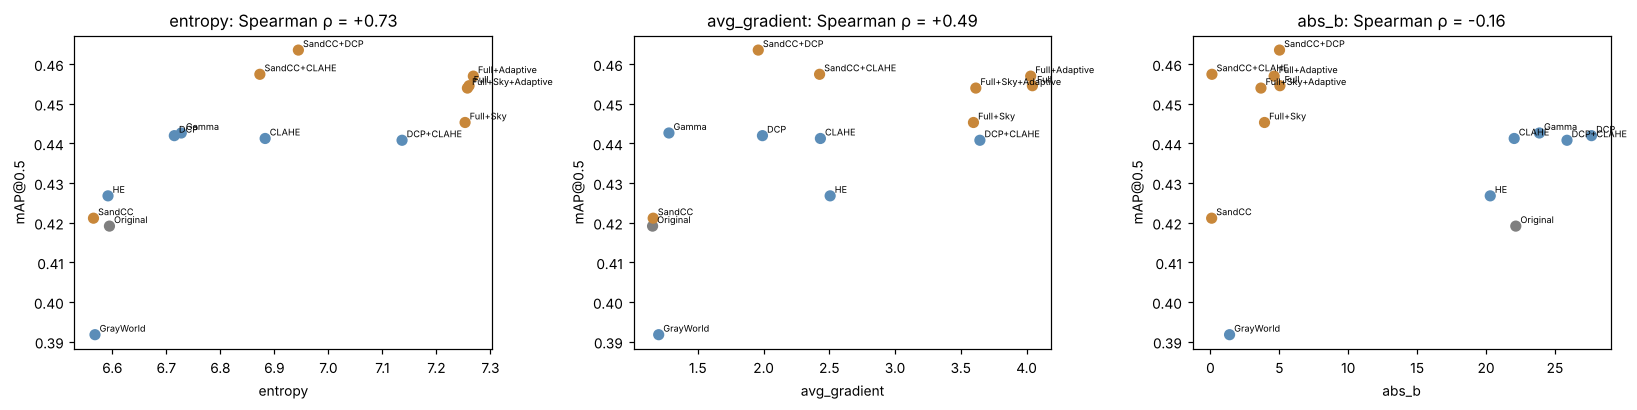

In [ ]:
qual = pd.DataFrame({m: pd.DataFrame(RESULTS[m]['quality']).T.mean() for m in METHODS}).T
qual['mAP50'] = res['mAP50']
qual.to_csv(OUT_DIR / 'table_quality.csv')
display(qual.style.format(precision=3).background_gradient(cmap='YlGn', axis=0))

corr = {k: spearmanr(qual[k], qual['mAP50']) for k in ['colorfulness', 'avg_gradient', 'entropy', 'abs_a', 'abs_b']}
print('Spearman correlation between quality metric and mAP@0.5 across methods:')
for k, (rho, p) in corr.items():
    print(f'  {k:<13} rho = {rho:+.2f}   p = {p:.3f}')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, k in zip(ax, ['entropy', 'avg_gradient', 'abs_b']):
    a.scatter(qual[k], qual['mAP50'], c=[colors[g] for g in res['group']], s=40)
    for m in qual.index:
        a.annotate(m, (qual.loc[m, k], qual.loc[m, 'mAP50']), fontsize=6, xytext=(3, 2), textcoords='offset points')
    a.set_xlabel(k); a.set_ylabel('mAP@0.5'); a.set_title(f'{k}: Spearman ρ = {corr[k][0]:+.2f}')
plt.tight_layout(); savefig('fig_quality_vs_map'); plt.show()

> **Note:** colour-cast and colourfulness metrics are not correlated with mAP; only entropy is (ρ = 0.73). Better-looking ≠ better for detection.

### 6.7 Different detector sizes (YOLOv8s, YOLOv8m)

In [ ]:
KEY = ['Original', 'CLAHE', 'Gamma', 'DCP', 'SandCC', 'SandCC+CLAHE', 'SandCC+DCP', 'Full', 'Full+Adaptive']
multi = {'yolov8n': {m: res.loc[m, 'mAP50'] for m in KEY}}
multi95 = {'yolov8n': {m: res.loc[m, 'mAP50_95'] for m in KEY}}
if RUN_MULTI_MODEL:
    for det in ['yolov8s', 'yolov8m']:
        multi[det], multi95[det] = {}, {}
        for m in KEY:
            r = metrics_from_records(per_image_records(run_method(m, det, with_quality=False)['dets']))
            multi[det][m], multi95[det][m] = r['mAP50'], r['mAP50_95']
multi = pd.DataFrame(multi); multi95 = pd.DataFrame(multi95)
rob = pd.concat({'mAP@0.5': multi, 'mAP@0.5:0.95': multi95}, axis=1)
rob.to_csv(OUT_DIR / 'table_multi_detector.csv')
display(rob.style.format(precision=4).background_gradient(cmap='YlGn', axis=0))
print('Gain of the best sand-specific vs. best generic method (mAP@0.5):')
for d in multi.columns:
    best_ours = multi.loc[[m for m in KEY if m in OURS], d]; best_gen = multi.loc[[m for m in KEY if m in GENERIC], d]
    print(f'  {d}: ours {best_ours.max():.4f} ({best_ours.idxmax()})  vs generic {best_gen.max():.4f} ({best_gen.idxmax()})'
          f'  vs original {multi.loc["Original", d]:.4f}')

Gain of the best sand-specific vs. best generic method (mAP@0.5):
  yolov8n: ours 0.4636 (SandCC+DCP)  vs generic 0.4426 (Gamma)  vs original 0.4192
  yolov8s: ours 0.5666 (SandCC+DCP)  vs generic 0.5680 (CLAHE)  vs original 0.5474
  yolov8m: ours 0.6270 (SandCC)  vs generic 0.5986 (CLAHE)  vs original 0.6055


> **Note:** the gain shrinks for larger detectors. YOLOv8s: sand-specific ≈ best generic. YOLOv8m: generic methods lower mAP; only the sand colour correction still helps (+2.2).

### 6.8 Runtime

In [ ]:
rt = pd.DataFrame({'preprocessing (ms/img)': {m: 1000 * RESULTS[m]['t_pre'] for m in METHODS},
                   'YOLOv8n inference (ms/img)': {m: 1000 * RESULTS[m]['t_det'] for m in METHODS}})
rt['total (ms/img)'] = rt.sum(1)
rt.to_csv(OUT_DIR / 'table_runtime.csv')
print(f'CPU: {os.cpu_count()} threads; images up to 1280 px wide (full resolution preprocessing)')
display(rt.round(1))

CPU: 2 threads; images up to 1280 px wide (full resolution preprocessing)


,preprocessing (ms/img),YOLOv8n inference (ms/img),total (ms/img)
Original,0.0,77.4,77.4
HE,3.3,75.7,78.9
CLAHE,14.1,76.6,90.7
Gamma,2.9,77.5,80.4
GrayWorld,28.2,77.4,105.6
DCP,135.6,80.4,215.9
DCP+CLAHE,143.3,77.0,220.2
SandCC,73.3,79.0,152.3
SandCC+CLAHE,84.2,78.3,162.5
SandCC+DCP,192.8,77.5,270.4


### 6.9 Detection examples (green = ground truth, red = detections)

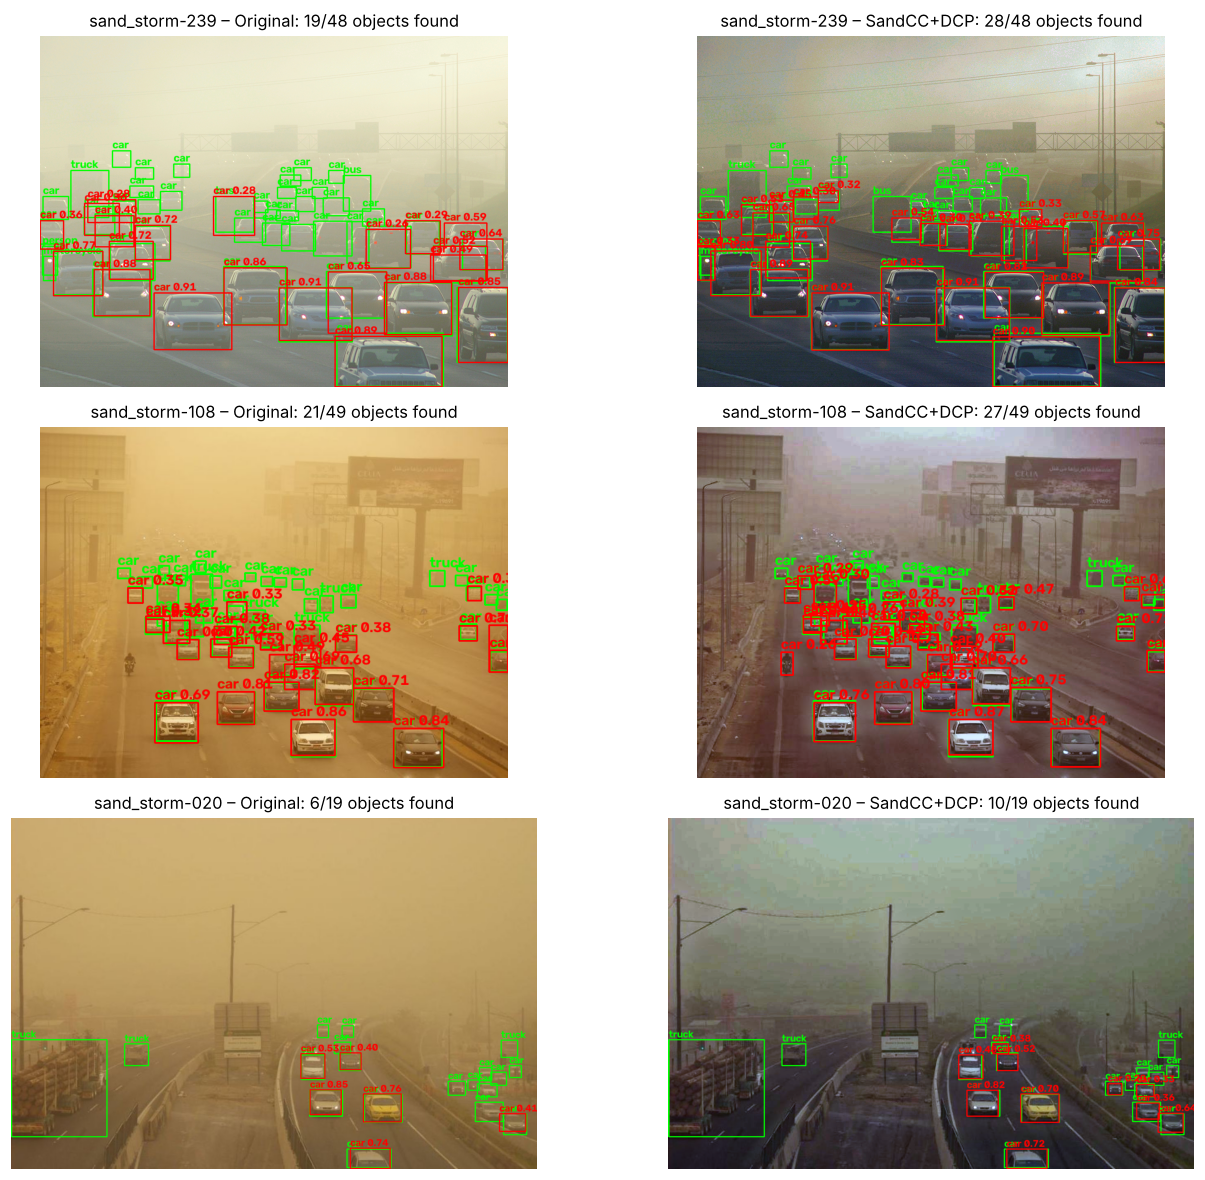

Best sand-specific configuration: SandCC+DCP


In [ ]:
def n_tp(rec):
    return int(rec['tp'][rec['conf'] >= CONF_PR, 0].sum())

BEST = res.loc[OURS, 'mAP50'].idxmax()
gain = pd.Series({n: n_tp(RECORDS[BEST][n]) - n_tp(RECORDS['Original'][n]) for n in NAMES}).sort_values(ascending=False)
picks = list(gain.index[:3])
fig, ax = plt.subplots(len(picks), 2, figsize=(13, 3.6 * len(picks)))
for i, n in enumerate(picks):
    img = imread(DATA_DIR / f'{n}.jpg')
    for j, m in enumerate(['Original', BEST]):
        shown = img if m == 'Original' else METHODS[m](img)
        d = RESULTS[m]['dets'][n]; d = d[d[:, 4] >= CONF_PR]
        vis = draw_boxes(draw_boxes(shown, GT[n], (0, 255, 0), thick=2), d, (0, 0, 255), with_conf=True, thick=2)
        ax[i, j].imshow(rgb(vis)); ax[i, j].axis('off')
        ax[i, j].set_title(f'{n} – {m}: {n_tp(RECORDS[m][n])}/{len(GT[n])} objects found')
plt.tight_layout(); savefig('fig_qualitative_detections'); plt.show()
print('Best sand-specific configuration:', BEST)

> **Note:** after restoration the detector finds many more distant, low-contrast vehicles.

### 6.10 Summary of key numbers

In [ ]:
best_gen = res.loc[GENERIC, 'mAP50'].idxmax()
print(f"Original:                     mAP@0.5 = {base['mAP50']:.4f}, mAP@0.5:0.95 = {base['mAP50_95']:.4f}, recall = {base['R']:.4f}")
print(f"Best generic ({best_gen:<9}):      mAP@0.5 = {res.loc[best_gen, 'mAP50']:.4f}, mAP@0.5:0.95 = {res.loc[best_gen, 'mAP50_95']:.4f}")
print(f"Best sand-specific ({BEST}): mAP@0.5 = {res.loc[BEST, 'mAP50']:.4f}, mAP@0.5:0.95 = {res.loc[BEST, 'mAP50_95']:.4f}")
print(f"  -> +{100*(res.loc[BEST,'mAP50']-base['mAP50']):.1f} points mAP@0.5 vs Original "
      f"({100*(res.loc[BEST,'mAP50']/base['mAP50']-1):.1f}% relative), "
      f"+{100*(res.loc[BEST,'mAP50']-res.loc[best_gen,'mAP50']):.1f} points vs best generic")
print(f"Highest recall: {res['R'].idxmax()} ({res['R'].max():.4f} vs {base['R']:.4f} original)")
print(f"Heavy dust: Original {sev_tab.loc['Original','heavy']:.4f} | generic DCP {sev_tab.loc['DCP','heavy']:.4f} | "
      f"{BEST} {sev_tab.loc[BEST,'heavy']:.4f}")

Original:                     mAP@0.5 = 0.4192, mAP@0.5:0.95 = 0.2859, recall = 0.5069
Best generic (Gamma    ):      mAP@0.5 = 0.4426, mAP@0.5:0.95 = 0.3025
Best sand-specific (SandCC+DCP): mAP@0.5 = 0.4636, mAP@0.5:0.95 = 0.3190
  -> +4.4 points mAP@0.5 vs Original (10.6% relative), +2.1 points vs best generic
Highest recall: Full (0.5888 vs 0.5069 original)
Heavy dust: Original 0.4223 | generic DCP 0.4090 | SandCC+DCP 0.4744


## 7. Final Observations
1. Sand-specific restoration (colour correction → DCP) gives the best detection with YOLOv8n: mAP@0.5 **0.464** vs. 0.419 (original) and 0.443 (best generic), +10.6% relative.
2. Colour correction must come **before** dehazing; on its own it does not help, and plain Gray-World even hurts.
3. The largest gain is in **heavy dust**, where generic DCP fails.
4. The gain comes from **recall** (0.51 → 0.57–0.59) with similar precision.
5. Severity-adaptive parameters help slightly; the sky mask **reduces** accuracy (negative result).
6. Image-quality metrics (colour cast, colourfulness) do not predict detection accuracy.
7. The benefit is largest for the small detector; for YOLOv8m only the colour correction remains useful.

## References
1. M. A. Kenk and M. Hassaballah, "DAWN: Vehicle detection in adverse weather nature dataset," arXiv:2008.05402, 2020. Data: doi:10.17632/766ygrbt8y.3
2. K. He, J. Sun and X. Tang, "Single image haze removal using dark channel prior," IEEE TPAMI, 33(12), 2341–2353, 2011. *(DCP)*
3. K. He, J. Sun and X. Tang, "Guided image filtering," IEEE TPAMI, 35(6), 1397–1409, 2013. *(guided filter)*
4. K. Zuiderveld, "Contrast limited adaptive histogram equalization," Graphics Gems IV, 474–485, 1994. *(CLAHE)*
5. G. Buchsbaum, "A spatial processor model for object colour perception," J. Franklin Inst., 310(1), 1–26, 1980. *(Gray-World)*
6. C. O. Ancuti, C. Ancuti, C. De Vleeschouwer and P. Bekaert, "Color balance and fusion for underwater image enhancement," IEEE TIP, 27(1), 379–393, 2018. *(channel compensation)*
7. Z. Shi et al., "Normalised gamma transformation-based contrast-limited adaptive histogram equalisation with colour correction for sand–dust image enhancement," IET Image Processing, 14(4), 747–756, 2020. *(Lab colour correction for sand)*
8. N. Otsu, "A threshold selection method from gray-level histograms," IEEE Trans. SMC, 9(1), 62–66, 1979. *(Otsu)*
9. D. Hasler and S. Süsstrunk, "Measuring colourfulness in natural images," Proc. SPIE 5007, 87–95, 2003. *(colourfulness)*
10. G. Jocher, A. Chaurasia and J. Qiu, *Ultralytics YOLOv8*, 2023, https://github.com/ultralytics/ultralytics
11. R. C. Gonzalez and R. E. Woods, *Digital Image Processing*, 4th ed., Pearson, 2018.